**Eye-Tracking & Neurocognitive Intelligence | Eye-Movement Modelling & Advanced AI | Presented by: Reza Saadatyar (2026)**

**05 | Robustness, Unseen-Person Evaluation and Model Synthesis**

![Eye-Movement Modelling independent participant Test evaluation and evidence integration](../../images/05_robustness_and_final_evaluation.svg)

**Objective:** Select a candidate using fixed Validation records from Notebooks 02–04, then evaluate frozen trained models once on the participant-disjoint Test partition of Notebook 01.

**Evaluation unit:** Original recording for metrics, participant for independence; temporal windows are aggregated to record probabilities before scoring. Eight models include a class-prior baseline, three classical classifiers, 1D-CNN, TCN, GRU and Transformer.

**Pilot versus main:** With the initial **ten people**, the Test scores remain exploratory diagnostics. In the main 20/30-person run, the highest source IDs not present in the initial ten-person pilot form the reserved Test partition. Selecting 20 versus 30 **after inspecting main Test** would undermine claims of an untouched final evaluation.

**Pre-registered principle:** Selection uses Validation Macro F1, then Balanced Accuracy, then a fixed complexity order. Do not adapt architecture, threshold, study size or feature selection to Test results. This notebook is not executed; no model scores are assumed.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**


In [ ]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_movement_modelling")

# ------------------------- 2. Scientific Computation -------------------------
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from IPython.display import display

# --------------------- 3. Research and Output Utilities ----------------------
from core.stage_outputs import ensure_stage_inputs
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab
from s2_data import (
    TASKS, load_protocol, load_windows, verify_temporal_source_alignment,
)
from s2_metrics import (
    FEATURE_COLUMN_NAMES, CLASS_TO_INDEX, metric_row,
    classical_record_predictions
)
from s2_training import (
    load_temporal, predict_windows, device_for_training,
)

# ----------------------------- 4. Output Folder ------------------------------
output_dir = root / "eye_movement_modelling" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Eye-Movement Modelling final-stage outputs:", output_dir)


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Eye-Movement Modelling final-stage outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output


**02. Recover Frozen Protocol and Validation Evidence**

Read the same Notebook 01 participant split and source feature table used in training. The four-stage Validation metrics from Notebooks 02–04 contain scores based on original **recordings**, not window counts. Do not read Test performance, predictions or labels to decide the candidate model.

Require all expected models and unique model labels; reject incompatible Validation record counts or person counts. The current stage reuses stored, trained models without fitting any new parameters.


In [ ]:
# ==================== 02. Recover Frozen Producer Outputs ====================

# -------------------- 1. Restore Explicit Current Inputs ---------------------
ensure_stage_inputs(output_dir, 1, (
    "01_record_features.csv", "01_split_assignments.csv",
    "01_sequence_windows.npz", "01_protocol.csv",
))
ensure_stage_inputs(output_dir, 2, (
    "02_validation_metrics.csv", "02_class_prior.joblib",
    "02_logistic_regression.joblib", "02_random_forest.joblib",
    "02_gradient_boosting.joblib",
))
ensure_stage_inputs(output_dir, 3, (
    "03_neural_validation_metrics.csv", "03_cnn.pt", "03_tcn.pt",
))
ensure_stage_inputs(output_dir, 4, (
    "04_neural_validation_metrics.csv", "04_gru.pt",
    "04_transformer.pt",
))

# ------------------- 2. Load Matching Protocol and Metrics -------------------
protocol = load_protocol(output_dir / "01_protocol.csv")
split = pd.read_csv(
    output_dir / "01_split_assignments.csv",
    dtype={"participant_id": str, "record_id": str},
)
features = pd.read_csv(
    output_dir / "01_record_features.csv",
    dtype={"participant_id": str, "record_id": str},
)
arrays = load_windows(output_dir / "01_sequence_windows.npz")
candidate_order = (
    "class_prior", "logistic_regression", "random_forest",
    "gradient_boosting", "cnn", "tcn", "gru", "transformer",
)
validation = pd.concat([
    pd.read_csv(output_dir / "02_validation_metrics.csv"),
    pd.read_csv(output_dir / "03_neural_validation_metrics.csv"),
    pd.read_csv(output_dir / "04_neural_validation_metrics.csv"),
], ignore_index=True)

# --------------------------- 3. Verify Comparison ----------------------------
if len(validation) != len(candidate_order) or (
    set(validation["model"]) != set(candidate_order)
) or validation["model"].duplicated().any():
    raise ValueError("Eight distinct saved Validation models are required")
if not validation["partition"].eq("validation").all():
    raise ValueError("Validation selection cannot use Test scores")
if validation["n_records"].nunique() != 1 or (
    validation["n_participants"].nunique() != 1
):
    raise ValueError("Validation models used different evaluation units")
actual_val = split.loc[split.split.eq("validation")]
if not validation.n_records.eq(len(actual_val)).all() or not (
    validation.n_participants.eq(actual_val.participant_id.nunique()).all()
):
    raise ValueError(
        "Saved model Validation scores are incompatible with the current "
        "source participant split. Rerun dependent model notebooks."
    )
alignment_counts = verify_temporal_source_alignment(arrays, split)
print("Aligned sequence windows by group:", alignment_counts)
print("Study mode:", protocol["purpose"])
print("Validation independent participants:",
      validation.n_participants.iloc[0])
display(validation[[
    "model", "n_records", "macro_f1", "balanced_accuracy", "accuracy",
]])


Aligned sequence windows by group: {'train': 576, 'validation': 192, 'test': 192}
Study mode: pilot
Validation independent participants: 2


,model,n_records,macro_f1,balanced_accuracy,accuracy
0,gradient_boosting,8,1.000,1.00,1.00
1,logistic_regression,8,1.000,1.00,1.00
2,random_forest,8,1.000,1.00,1.00
3,class_prior,8,0.100,0.25,0.25
4,cnn,8,1.000,1.00,1.00
5,tcn,8,1.000,1.00,1.00
6,transformer,8,0.375,0.50,0.50
7,gru,8,0.100,0.25,0.25


**03. Select the Candidate from Validation Only**

Sort fixed Validation metrics by descending Macro F1, then Balanced Accuracy, then predefined model order for exact ties. Record the chosen model and the decision **before executing the Test cell**. Other models may also be scored later for exploratory comparison, but none may replace the selected primary model based on Test.

A two-person Test partition in the ten-person Pilot is too small for strong inferential or superiority claims; this remains clearly labelled pilot evidence.


Validation-selected model: logistic_regression


,model,macro_f1,balanced_accuracy
0,logistic_regression,1.000,1.00
1,random_forest,1.000,1.00
2,gradient_boosting,1.000,1.00
3,cnn,1.000,1.00
4,tcn,1.000,1.00
5,transformer,0.375,0.50
6,class_prior,0.100,0.25
7,gru,0.100,0.25


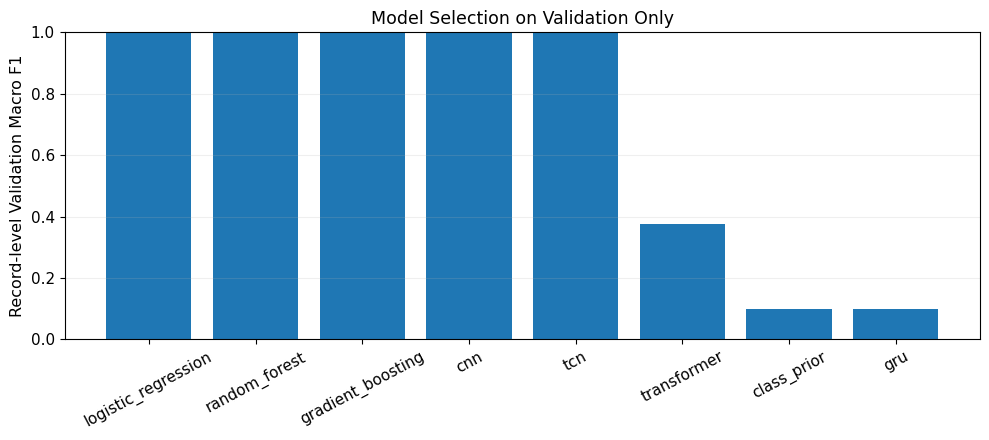

In [ ]:
# =================== 03. Freeze Validation-Based Selection ===================

# --------------------- 1. Apply A Priori Decision Order ----------------------
priority = {name: i for i, name in enumerate(candidate_order)}
selection = validation.copy()
selection["tie_priority"] = selection.model.map(priority)
selection = selection.sort_values(
    ["macro_f1", "balanced_accuracy", "tie_priority"],
    ascending=[False, False, True],
).reset_index(drop=True)
selected_name = str(selection.loc[0, "model"])
decision = {
    "selected_model": selected_name,
    "selection_rule": "validation_macro_f1_then_balanced_accuracy_then_order",
    "purpose": protocol["purpose"],
    "test_used_in_selection": False,
    "validation_n_people": int(selection.n_participants.iloc[0]),
}
pd.DataFrame([decision]).to_csv(
    output_dir / "05_model_selection.csv", index=False,
)
(output_dir / "05_model_selection.json").unlink(missing_ok=True)
print("Validation-selected model:", selected_name)
display(selection[["model", "macro_f1", "balanced_accuracy"]])

# -------------------------- 2. Visualise Selection ---------------------------
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(selection["model"], selection["macro_f1"])
ax.set(ylabel="Record-level Validation Macro F1", ylim=(0, 1),
       title="Model Selection on Validation Only")
ax.tick_params(axis="x", rotation=28)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "05_validation_selection.png")
plt.show()


**04. Score Frozen Models on Held-Out Participant Test**

**This is the first Test evaluation in the sequence.** Load the already fitted scikit-learn Pipeline artefacts and the saved PyTorch state dictionaries; do not refit scalers, feature transformations, class weights, neural layers or hyperparameters. Temporal Test windows are mapped to original source record IDs and their probabilities averaged within each record.

Report Accuracy, fixed-label Macro F1 and Balanced Accuracy across the same held-out recordings, explicitly preserving their source participant identities. Any comparison across all eight Test models is secondary and exploratory; the primary model was selected from Validation only.


In [ ]:
# ====================== 04. Held-Out Record Evaluation =======================

# ------------------- 1. Verify Test Source Record Identity -------------------
test = features.loc[features.split.eq("test")].copy()
expected = set(split.loc[split.split.eq("test"), "record_id"])
if test.empty or set(test.record_id) != expected:
    raise ValueError("Test record identities missing or incompatible")
test_participants = test.participant_id.nunique()
print("Held-out people:", test_participants)
print("Held-out original task records:", len(test))

# ----------------------- 2. Score Classical Pipelines ------------------------
predictions = []
for name in candidate_order[:4]:
    model = joblib.load(output_dir / f"02_{name}.joblib")
    pred = classical_record_predictions(
        model, test, model_name=name, partition="test",
    )
    predictions.append(pred)

# ---------------------- 3. Score Frozen Temporal Models ----------------------
membership = dict(zip(split.record_id.astype(str), split.split))
record_roles = np.asarray([
    membership[str(r)] for r in arrays["record_id"]
])
test_mask = record_roles == "test"
for name, stage in (("cnn", "03"), ("tcn", "03"),
                    ("gru", "04"), ("transformer", "04")):
    model, state = load_temporal(output_dir / f"{stage}_{name}.pt")
    proba = predict_windows(
        model, arrays["x"][test_mask], device=device_for_training(),
    )
    from s2_metrics import record_probabilities
    pred = record_probabilities(
        arrays["record_id"][test_mask],
        arrays["y"][test_mask], proba,
    )
    pred["model"] = name
    pred["partition"] = "test"
    pred = pred.merge(
        test[["record_id", "participant_id", "task"]],
        on="record_id", how="inner", validate="one_to_one",
    )
    predictions.append(pred)

# ----------------- 4. Persist Comparable Source-Level Scores -----------------
all_predictions = pd.concat(predictions, ignore_index=True)
if any(set(p.record_id) != expected for p in predictions):
    raise ValueError("Not all frozen models scored the same Test records")
all_predictions.to_csv(output_dir / "05_test_predictions.csv", index=False)
results = []
for name, frame in all_predictions.groupby("model", sort=False):
    result = metric_row(
        frame.target_index, frame.pred_index, model=name,
        partition="test", n_participants=test_participants,
    )
    result["selected_primary"] = bool(name == selected_name)
    result["study_purpose"] = protocol["purpose"]
    results.append(result)
test_metrics = pd.DataFrame(results).sort_values("model")
test_metrics.to_csv(output_dir / "05_test_metrics.csv", index=False)
display(test_metrics)


Held-out people: 2
Held-out original task records: 8


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy,selected_primary,study_purpose
0,class_prior,test,8,2,0.250,0.100000,0.250,False,pilot
4,cnn,test,8,2,0.750,0.733333,0.750,False,pilot
3,gradient_boosting,test,8,2,0.875,0.866667,0.875,False,pilot
6,gru,test,8,2,0.250,0.100000,0.250,False,pilot
1,logistic_regression,test,8,2,0.875,0.866667,0.875,True,pilot
2,random_forest,test,8,2,0.875,0.866667,0.875,False,pilot
5,tcn,test,8,2,0.750,0.741667,0.750,False,pilot
7,transformer,test,8,2,0.500,0.333333,0.500,False,pilot


**05. Examine Primary Errors and Participant-Level Heterogeneity**

Show a confusion matrix for the **previously selected model**, with FXS/HSS/RAN/TEX in fixed order. Also report descriptive scores per independent Test participant to expose possible performance heterogeneity, rather than hiding it in a single pooled mean.

With only two Test people in the Pilot, neither a bootstrap interval nor a significance test can substantiate generalisation. Do not select a different model based on which one looks better on Test.


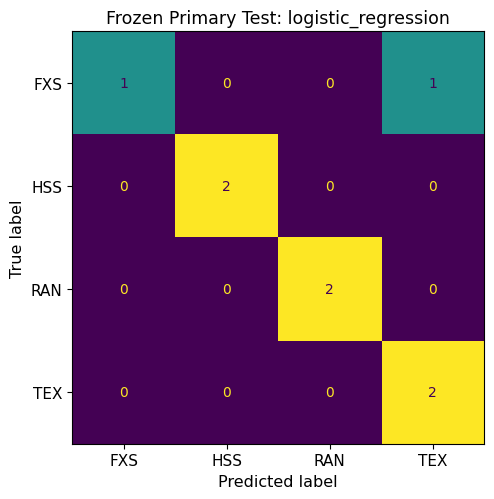

,model,participant_id,n_records,macro_f1,balanced_accuracy,accuracy
0,class_prior,001,4,0.100000,0.25,0.25
1,class_prior,005,4,0.100000,0.25,0.25
2,cnn,001,4,1.000000,1.00,1.00
3,cnn,005,4,0.333333,0.50,0.50
4,gradient_boosting,001,4,1.000000,1.00,1.00
5,gradient_boosting,005,4,0.666667,0.75,0.75
6,gru,001,4,0.100000,0.25,0.25
7,gru,005,4,0.100000,0.25,0.25
8,logistic_regression,001,4,1.000000,1.00,1.00
9,logistic_regression,005,4,0.666667,0.75,0.75


In [ ]:
# ================= 05. Inspect Frozen Primary Test Evidence ==================

# ----------------- 1. Display Primary Model Confusion Matrix -----------------
primary = all_predictions.loc[
    all_predictions.model.eq(selected_name)
].copy()
matrix = confusion_matrix(
    primary.target_index, primary.pred_index,
    labels=range(len(TASKS)),
)
fig, ax = plt.subplots(figsize=(6.4, 5.1))
ConfusionMatrixDisplay(
    matrix, display_labels=TASKS,
).plot(ax=ax, colorbar=False, values_format="d")
ax.set_title(f"Frozen Primary Test: {selected_name}")
fig.tight_layout()
save_figure(fig, output_dir / "05_selected_test_confusion.png")
plt.show()

# ----------------- 2. Describe Independent Test Participants -----------------
individual = []
for (name, person), group in all_predictions.groupby(
    ["model", "participant_id"], sort=True,
):
    row = metric_row(
        group.target_index, group.pred_index,
        model=name, partition="test_person",
        n_participants=1,
    )
    row["participant_id"] = person
    individual.append(row)
groupwise = pd.DataFrame(individual)
groupwise.to_csv(output_dir / "05_groupwise_test_metrics.csv", index=False)
display(groupwise[[
    "model", "participant_id", "n_records", "macro_f1",
    "balanced_accuracy", "accuracy",
]].head(20))


**06. Run Descriptive Validation-Only Robustness Check**

For the selected model, compare Validation predictions under an explicitly described feature perturbation **without refitting**: remove pupil features from classical models or zero relative position channels in temporal models. This tests model sensitivity to a particular input intervention and is **not a causal feature importance explanation**.

The perturbation is applied on Validation, not Test, so it cannot drive a second test-based model selection. If the selected model is the no-signal prior, report that input-feature perturbation is not applicable.


,model,condition,macro_f1,n_records
0,logistic_regression,original_validation,1.0,8
1,logistic_regression,pupil_features_masked,1.0,8


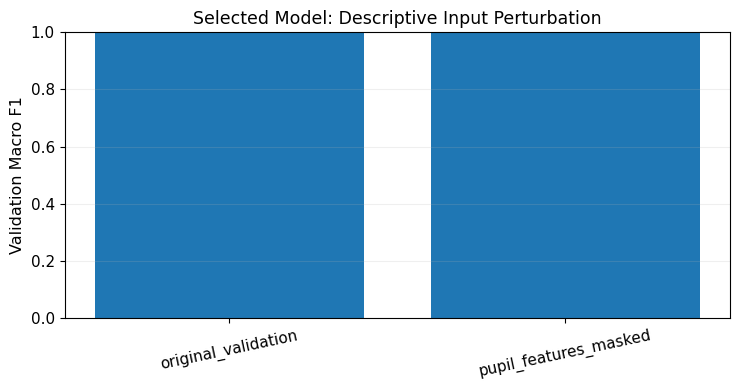

In [ ]:
# ================= 06. Inspect Validation-Only Perturbations =================

# --------------------- 1. Select Validation Source Units ---------------------
valid_records = features.loc[features.split.eq("validation")].copy()
base = validation.loc[validation.model.eq(selected_name)].iloc[0]
robust = [{
    "model": selected_name, "condition": "original_validation",
    "macro_f1": float(base.macro_f1),
    "n_records": int(base.n_records),
}]

# ------------------ 2. Apply One Defined Input Intervention ------------------
if selected_name in candidate_order[:4]:
    model = joblib.load(output_dir / f"02_{selected_name}.joblib")
    altered = valid_records.copy()
    altered[["pupil_coverage", "pupil_median_uncalibrated"]] = np.nan
    pred = classical_record_predictions(
        model, altered, model_name=selected_name,
        partition="validation",
    )
    score = metric_row(
        pred.target_index, pred.pred_index, model=selected_name,
        partition="validation", n_participants=valid_records.participant_id.nunique(),
    )
    condition = "pupil_features_masked"
elif selected_name in candidate_order[4:]:
    stage = "03" if selected_name in ("cnn", "tcn") else "04"
    model, _ = load_temporal(output_dir / f"{stage}_{selected_name}.pt")
    valid_mask = record_roles == "validation"
    altered = arrays["x"][valid_mask].copy()
    altered[:, :, 0:2] = 0
    proba = predict_windows(
        model, altered, device=device_for_training(),
    )
    from s2_metrics import record_probabilities
    pred = record_probabilities(
        arrays["record_id"][valid_mask],
        arrays["y"][valid_mask], proba,
    )
    score = metric_row(
        pred.target_index, pred.pred_index, model=selected_name,
        partition="validation", n_participants=valid_records.participant_id.nunique(),
    )
    condition = "relative_xy_channels_masked"
else:
    raise ValueError("Unknown selected model")
robust.append({
    "model": selected_name, "condition": condition,
    "macro_f1": score["macro_f1"], "n_records": score["n_records"],
})
robustness = pd.DataFrame(robust)
robustness.to_csv(
    output_dir / "05_robustness_validation.csv", index=False,
)
display(robustness)

# ------------------------- 3. Save Robustness Figure -------------------------
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(robustness.condition, robustness.macro_f1)
ax.set(ylabel="Validation Macro F1", ylim=(0, 1),
       title="Selected Model: Descriptive Input Perturbation")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "05_validation_robustness.png")
plt.show()


**07. Compare Models Without Post-Hoc Test Selection**

Produce a full descriptive Test comparison, highlighting the candidate selected before opening Test. Show differences by model family and the participant count. A higher secondary-model Test result does not replace the selected primary candidate or retroactively justify hyperparameter changes.

This is an **internal GazeBase source and Task-identity exercise**. It does not predict comprehension, health, attention or a general neurocognitive outcome. Any claims of cross-person generalisation must acknowledge the limited independent Test support and the source-ID-based cohort selection.


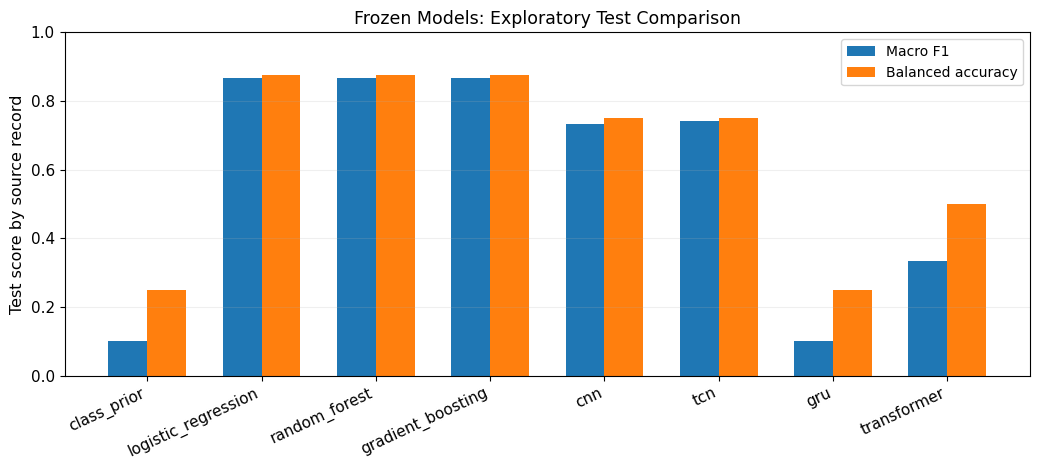

Preselected model: logistic_regression
Study purpose: pilot
Test participants: 2


In [ ]:
# ==================== 07. Display Frozen Test Comparison =====================

# ------------------------- 1. Common Record Metrics --------------------------
ordered = test_metrics.set_index("model").reindex(candidate_order)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
pos = np.arange(len(ordered))
ax.bar(pos - 0.17, ordered.macro_f1, width=0.34,
       label="Macro F1")
ax.bar(pos + 0.17, ordered.balanced_accuracy, width=0.34,
       label="Balanced accuracy")
ax.set_xticks(pos, ordered.index, rotation=25, ha="right")
ax.set(ylabel="Test score by source record", ylim=(0, 1),
       title="Frozen Models: Exploratory Test Comparison")
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
save_figure(fig, output_dir / "05_final_model_comparison.png")
plt.show()
print("Preselected model:", selected_name)
print("Study purpose:", protocol["purpose"])
print("Test participants:", test_participants)


**08. Interpretation, Artefact Retention and Download**

Save the Validation-based selection, unmodified frozen Test predictions, record-level and participant-level Test metrics, source-level confusion plot, and Validation-only input perturbation. Keep the distinction between **pilot** and **main** evaluation explicit in the report.

The initial 10-person pilot is for functional checking and cannot establish a robust model comparison. Choose the intended 20/30-person main cohort **before** exposing its reserved Test, then rerun Notebooks 01–05 using compatible current inputs and the same prespecified methods.

No model weights or output CSVs are automatically published. This notebook completes the proposed analysis code, not an observed training result until it is executed.


In [ ]:
# ====================== 08. Export Final-Stage Evidence ======================
download_outputs_from_colab("eye_movement_modelling/output", "05")


Primary model selection: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output/05_model_selection.csv
Test record metrics: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output/05_test_metrics.csv
Test participant metrics: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output/05_groupwise_test_metrics.csv
Validation-only robustness: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output/05_robustness_validation.csv
Study mode: pilot
------------------------------------------------------------------------
Notebook 05
Files packaged: 9
  + 05_final_model_comparison.png
  + 05_groupwise_test_metrics.csv
  + 05_model_selection.csv
  + 05_robustness_validation.csv
  + 05_selected_test_confusion.png
  + 05_test_metrics.csv
  + 05_test_predictions.csv
  + 05_validation_robustness.png
  + 05_validation_selection.png
Download ZIP from Colab Contents: /content/eye_movement_modelling_Notebook_05